# Computer Vision - P2

### *Carefully read the following instructions before start coding.*

### **Recommended Preparation**

Before starting P2, it is **recommended that you complete the `p2_tutorial` first**. The tutorial introduces the key concepts and steps needed to complete the practice successfully. Completing it beforehand will help you understand the requirements and avoid common mistakes.


==============================================================================================
## **Practice 2: Image Filtering and Edge Detection**


==============================================================================================

### Main Topics

The main topics covered in this **practical exercise** are:

1. **Image smoothing and convolution** — Exercises 2.1, 2.2, 2.3, and 2.4
2. **Edge detection** — Exercises 2.5, 2.6, and 2.7

To complete this practical exercise, you should understand the following concepts:

* Linear filters
* Histograms
* Convolution
* Image edges

For additional information, refer to the following chapters of *Computer Vision: Algorithms and Applications* by Richard Szeliski:

* **Chapter 3 — Image Processing:** Point Operators and Linear Filtering
* **Chapter 4 — Feature Detection and Matching:** Edges
---

## **2.1 RGB histogram visualization**

**a)** Read the image `./images_notebook/plugs.png` and visualize the **RGB image** and each of its channels (**R, G, and B**) separately. Print the **image shape** and **data type**.

<img src="images_notebook/plugs.png">

> Expected output is illustrated below:

<img src="images_notebook/plugsb.jpg">

Data type: uint8
Shape: (533, 800, 3)


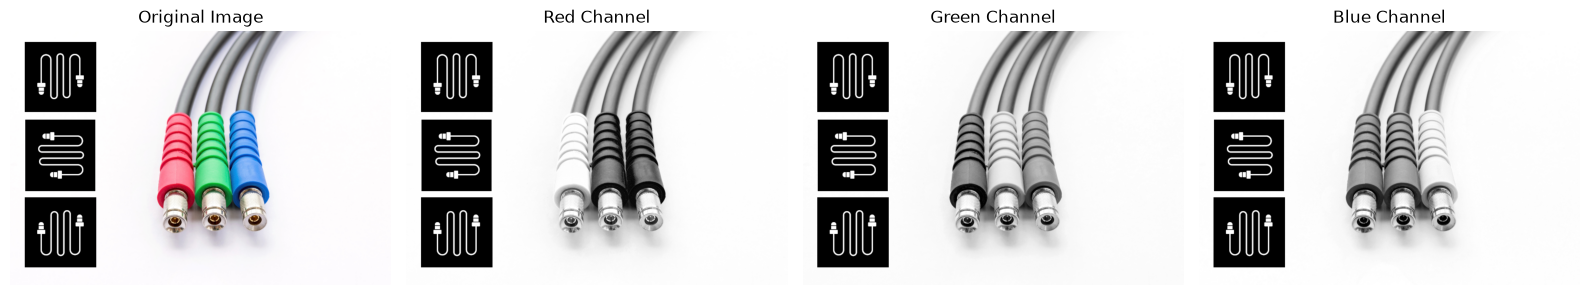

In [2]:
# Import the required libraries.
from skimage import io
from matplotlib import pyplot as plt
import numpy as np
from skimage import img_as_float
from skimage.color import rgb2gray

# Your solution

# Read the RGB image.
img_cable = io.imread("images_notebook/plugs.png")

# Print the data type and dimensions of the image.
print("Data type:", img_cable.dtype)
print("Shape:", img_cable.shape)

# Create a figure with four plots arranged in one row.
# The plots will show the original RGB image and its three color channels.
fig, ax = plt.subplots(1, 4, figsize=(16, 5))

# Display the original RGB image.
ax[0].imshow(img_cable)
ax[0].axis("off")
ax[0].set_title("Original Image")

# Extract the Red channel (channel 0).
img_cable_r = img_cable[:, :, 0]

# Display the Red channel as a grayscale image.
ax[1].imshow(img_cable_r, cmap="gray", vmin=0, vmax=255)
ax[1].axis("off")
ax[1].set_title("Red Channel")

# Extract the Green channel (channel 1).
img_cable_g = img_cable[:, :, 1]

# Display the Green channel as a grayscale image.
ax[2].imshow(img_cable_g, cmap="gray", vmin=0, vmax=255)
ax[2].axis("off")
ax[2].set_title("Green Channel")

# Extract the Blue channel (channel 2).
img_cable_b = img_cable[:, :, 2]

# Display the Blue channel as a grayscale image.
ax[3].imshow(img_cable_b, cmap="gray", vmin=0, vmax=255)
ax[3].axis("off")
ax[3].set_title("Blue Channel")

# Adjust the layout and display the figure.
plt.tight_layout()
plt.show()

**b)** Create a function named `rgb_im_hist(img, nbins=8)` that takes an **RGB image** as input and:

* Displays the **original RGB image**.
* Computes and displays the **histogram of each color channel (R, G, and B)**.
* Converts the image to **grayscale** and displays its histogram.
* Arranges all results **side by side** with appropriate captions.
* Uses `nbins` as an **input parameter** to specify the number of histogram bins. The value of `nbins` can range from **2 to 256**.

> **Note:** Test your function with `nbins = 8, 16, 32, 64, 128,` and `256` to make sure it works correctly for different numbers of histogram bins.

> Expected output is illustrated below (for `nbins=8`):

<img src="images_notebook/rgb_img_hist.jpg">

**Help:** [matplotlib image tutorial](https://matplotlib.org/users/image_tutorial.html)

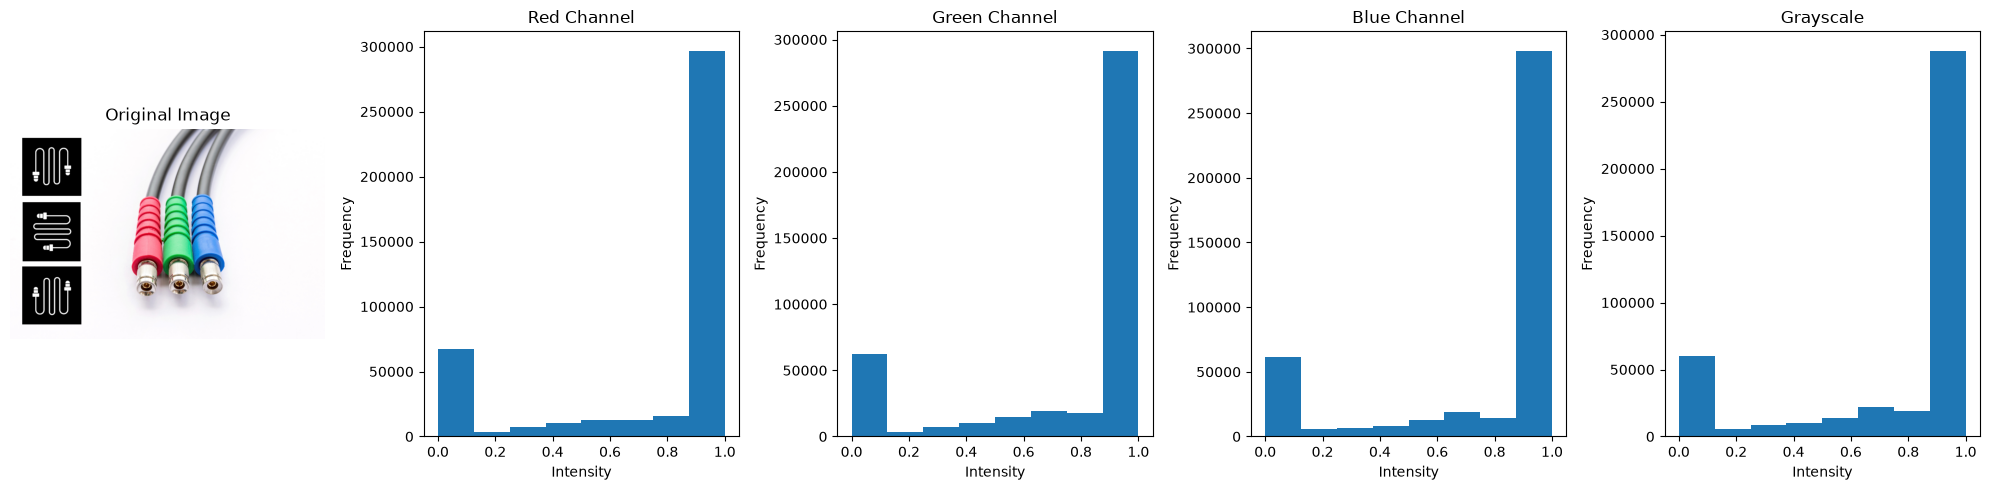

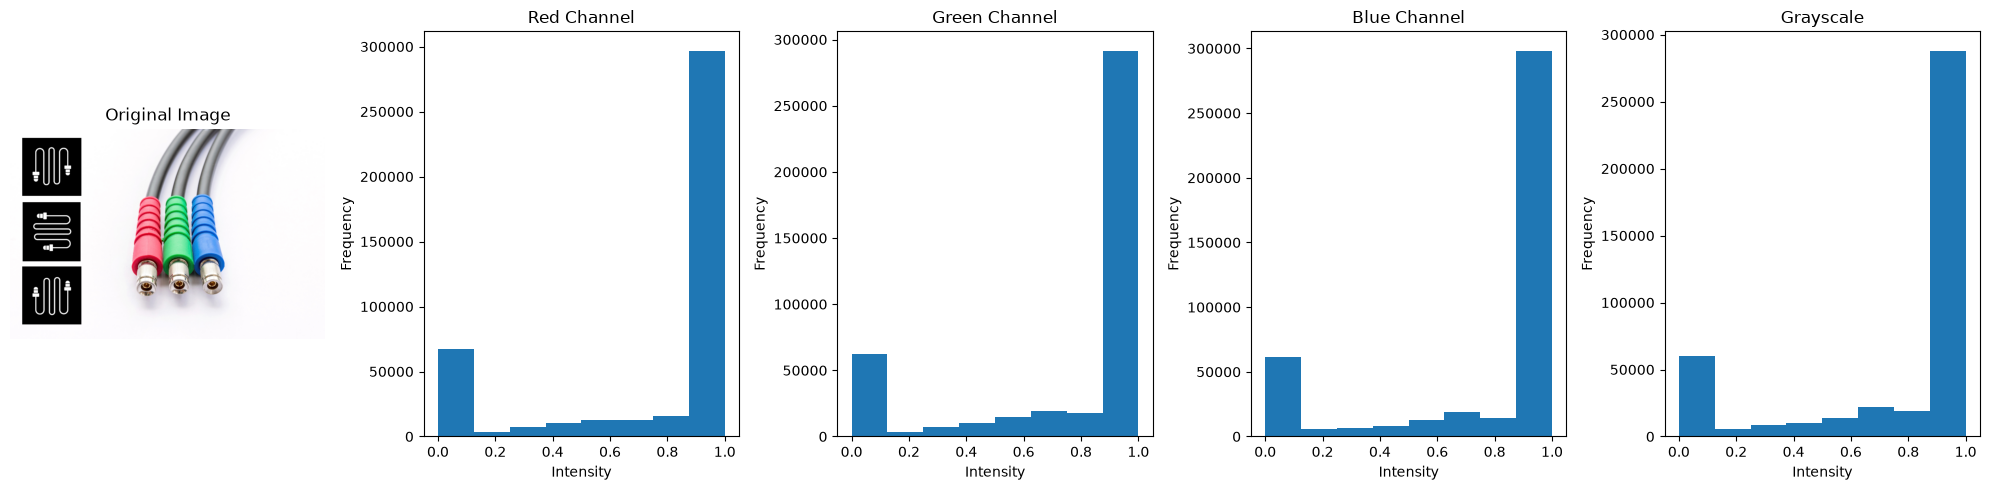

In [3]:
# your solution

# =====================================
# SOLUTION 1: Using plt.hist()
# =====================================

# Import the required libraries.
from skimage import io
from skimage.color import rgb2gray
from matplotlib import pyplot as plt
import numpy as np


def rgb_im_hist(img, nbins=8):
    """
    Display an RGB image and its histograms.

    Parameters:
        img: RGB image.
        nbins: Number of histogram bins (2 to 256).
    """

    # Check that the number of bins is within the allowed range.
    if not 2 <= nbins <= 256:
        raise ValueError("nbins must be between 2 and 256.")

    # Convert the image to grayscale.
    img_gray = rgb2gray(img)

    # Create a figure with five plots:
    # original image + R, G, B, and grayscale histograms.
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))

    # Display the original RGB image.
    ax[0].imshow(img)
    ax[0].axis("off")
    ax[0].set_title("Original Image")

    # Display the histogram of the Red channel.
    ax[1].hist(img[:, :, 0].ravel(), bins=nbins)
    ax[1].set_title("Red Channel")
    ax[1].set_xlabel("Intensity")
    ax[1].set_ylabel("Frequency")

    # Display the histogram of the Green channel.
    ax[2].hist(img[:, :, 1].ravel(), bins=nbins)
    ax[2].set_title("Green Channel")
    ax[2].set_xlabel("Intensity")
    ax[2].set_ylabel("Frequency")

    # Display the histogram of the Blue channel.
    ax[3].hist(img[:, :, 2].ravel(), bins=nbins)
    ax[3].set_title("Blue Channel")
    ax[3].set_xlabel("Intensity")
    ax[3].set_ylabel("Frequency")

    # Display the histogram of the grayscale image.
    ax[4].hist(img_gray.ravel(), bins=nbins)
    ax[4].set_title("Grayscale")
    ax[4].set_xlabel("Intensity")
    ax[4].set_ylabel("Frequency")

    # Adjust the layout and display the figure.
    plt.tight_layout()
    plt.show()


# Read the image.
img_cable = io.imread("images_notebook/plugs.png")

# Convert the image to floating point before computing the histograms.
img_cable = img_cable.astype(float) / 255

# Call the function with 8 histogram bins.
rgb_im_hist(img_cable, nbins=8)


# =====================================
# SOLUTION 2: Using exposure.histogram()
# =====================================

# Import the required libraries.
from skimage import io, exposure
from skimage.color import rgb2gray
from matplotlib import pyplot as plt


def rgb_im_hist(img, nbins=8):
    """
    Display an RGB image and its histograms using exposure.histogram().

    Parameters:
        img: RGB image.
        nbins: Number of histogram bins (2 to 256).
    """

    # Check that the number of bins is within the allowed range.
    if not 2 <= nbins <= 256:
        raise ValueError("nbins must be between 2 and 256.")

    # Convert the image to grayscale.
    img_gray = rgb2gray(img)

    # Compute the histogram of each RGB channel.
    hist_r, bins_r = exposure.histogram(img[:, :, 0], nbins=nbins)
    hist_g, bins_g = exposure.histogram(img[:, :, 1], nbins=nbins)
    hist_b, bins_b = exposure.histogram(img[:, :, 2], nbins=nbins)

    # Compute the histogram of the grayscale image.
    hist_gray, bins_gray = exposure.histogram(img_gray, nbins=nbins)

    # Create a figure with five plots:
    # original image + R, G, B, and grayscale histograms.
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))

    # Display the original RGB image.
    ax[0].imshow(img)
    ax[0].axis("off")
    ax[0].set_title("Original Image")

    # Display the Red channel histogram.
    ax[1].bar(bins_r, hist_r, width=bins_r[1] - bins_r[0])
    ax[1].set_title("Red Channel")
    ax[1].set_xlabel("Intensity")
    ax[1].set_ylabel("Frequency")

    # Display the Green channel histogram.
    ax[2].bar(bins_g, hist_g, width=bins_g[1] - bins_g[0])
    ax[2].set_title("Green Channel")
    ax[2].set_xlabel("Intensity")
    ax[2].set_ylabel("Frequency")

    # Display the Blue channel histogram.
    ax[3].bar(bins_b, hist_b, width=bins_b[1] - bins_b[0])
    ax[3].set_title("Blue Channel")
    ax[3].set_xlabel("Intensity")
    ax[3].set_ylabel("Frequency")

    # Display the grayscale histogram.
    ax[4].bar(bins_gray, hist_gray, width=bins_gray[1] - bins_gray[0])
    ax[4].set_title("Grayscale")
    ax[4].set_xlabel("Intensity")
    ax[4].set_ylabel("Frequency")

    # Adjust the layout and display the figure.
    plt.tight_layout()
    plt.show()


# Read the image.
img_cable = io.imread("images_notebook/plugs.png")

# Convert the image to floating point before computing the histograms.
img_cable = img_cable.astype(float) / 255

# Call the function with 8 histogram bins.
rgb_im_hist(img_cable, nbins=8)

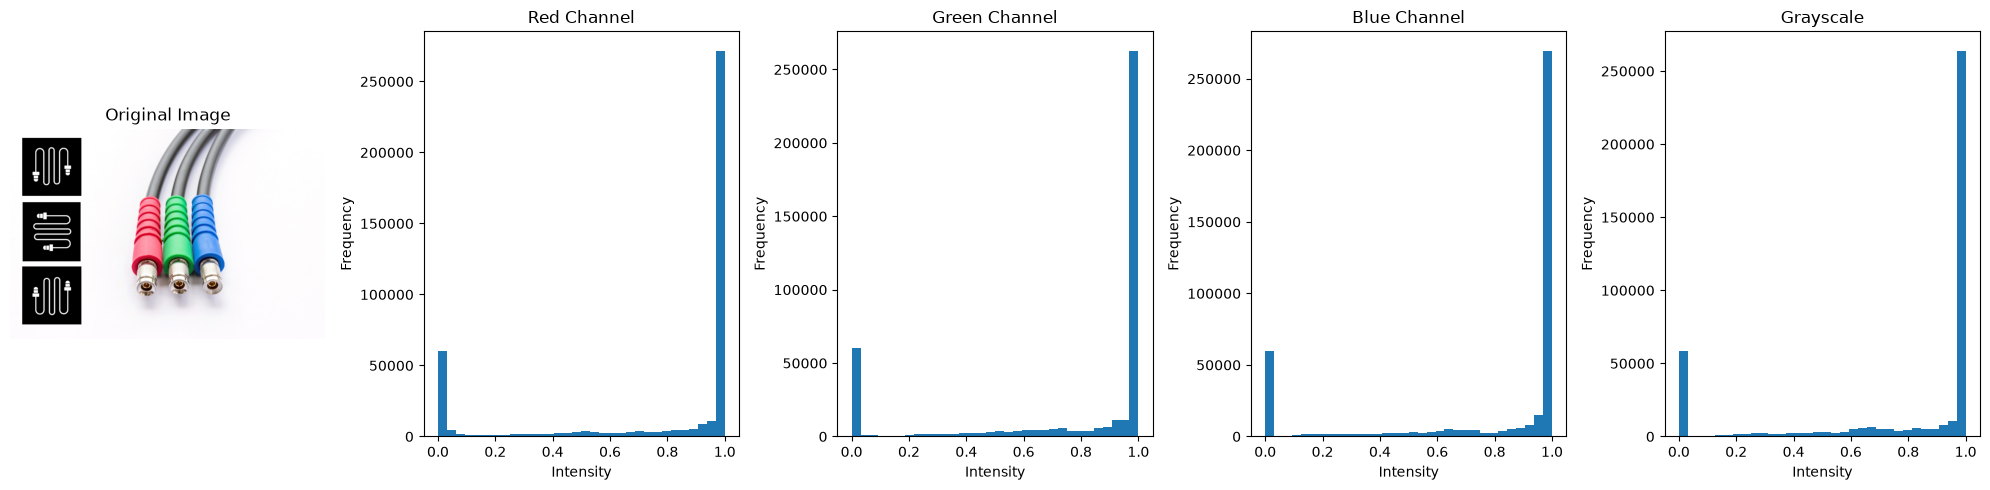

In [4]:
# Call the function with 32 histogram bins.
rgb_im_hist(img_cable, nbins=32)

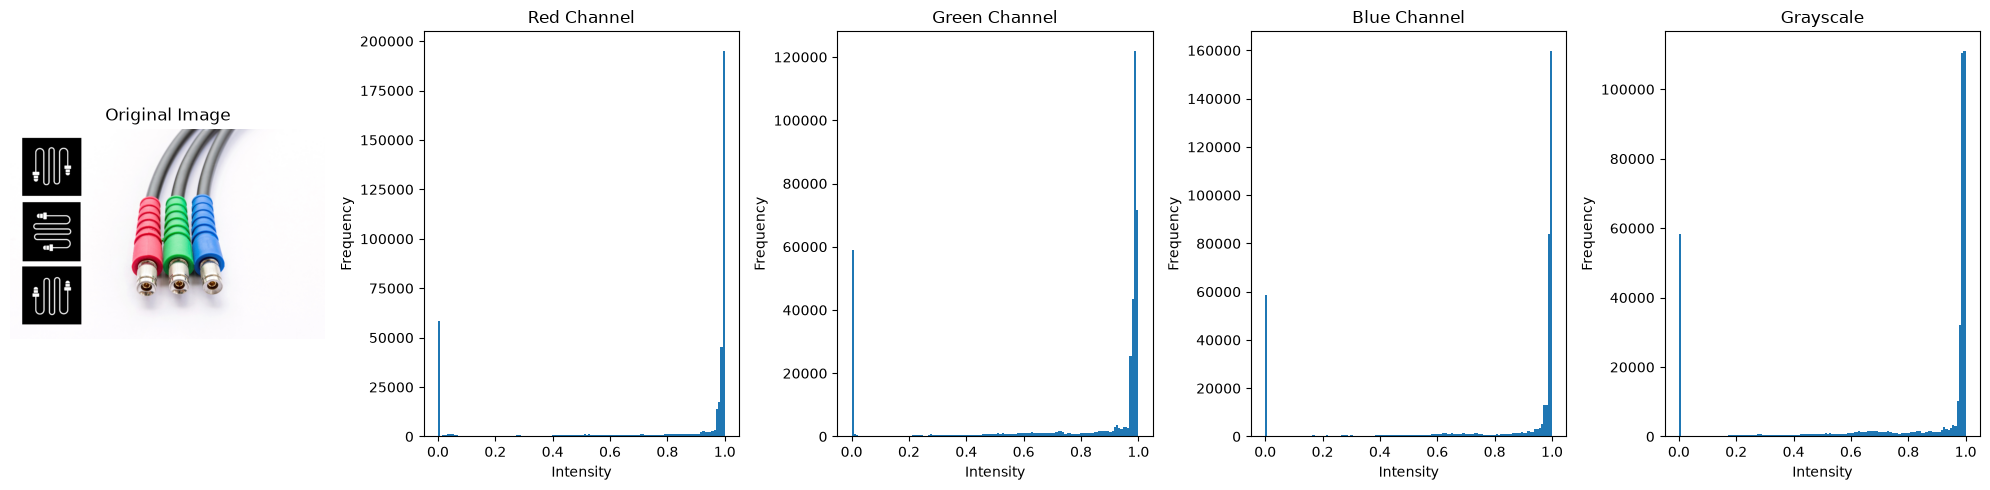

In [5]:
# Call the function with 128 histogram bins.
rgb_im_hist(img_cable, nbins=128)

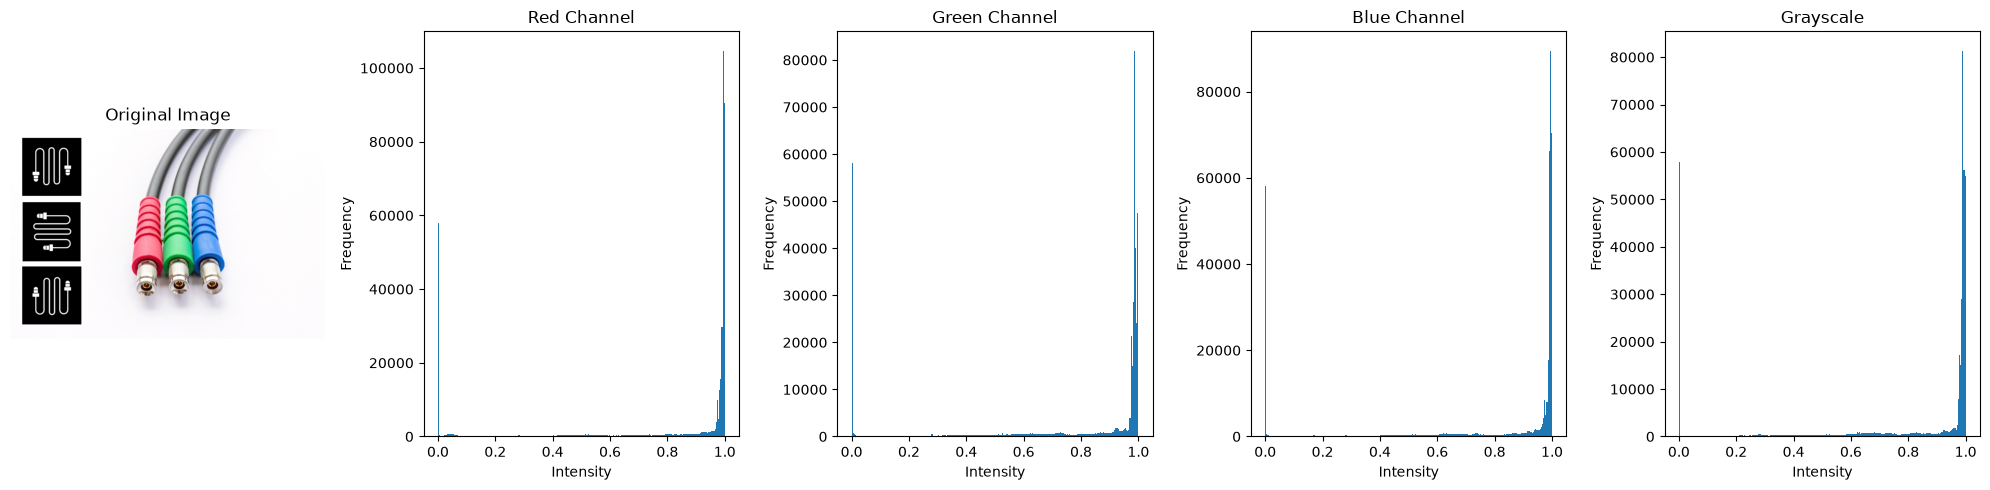

In [6]:
# Call the function with 256 histogram bins.
rgb_im_hist(img_cable, nbins=256)

### Discussion

Analyse the plots obtained with different values of `nbins`. In particular, consider:

* How increasing the number of bins affects the **appearance and level of detail** of the histograms.
* The differences between the histograms of the **R, G, and B channels**.
* The relationship between the **RGB channel histograms** and the **grayscale histogram**.
* Which values of `nbins` provide a more useful representation of the image's intensity distribution.
---

## **2.2 Grayscale and RGB images filtering (convolutions)**

**a)** Read the image `./images_notebook/oryx.png`. Resize the image to **256 × 256 pixels** and convert it to grayscale (store the result as `oryx_gray`).

Apply the following convolutions:

1. Convolve `oryx_gray` with the horizontal mask

   `mask_h1d = [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]`

   using the `ndimage.convolve()` function from the `scipy` package.

2. Convolve `oryx_gray` with the transpose of the mask used in part (1).

3. Convolve `oryx_gray` with a uniform **two-dimensional** mask of size **15 × 15**, where all values are equal to 1.

For each resulting image, determine the **minimum value**, **maximum value**, and **data type**.

**Note:** The `convolve()` function performs **multidimensional convolution**. Therefore, a one-dimensional horizontal mask must be represented as `[[1, ..., 1]]`.

**Note:** Before applying `convolve()`, normalize each mask so that the sum of all its elements is equal to 1.


In [9]:
#your solution

from skimage.transform import resize
from scipy.ndimage import convolve

# Read the RGB image.
img_oryx = io.imread("images_notebook/oryx.jpg")

# Use skimage to scale the image oryx to a 256x256 image
oryx_resized = img_oryx.copy() # Here you can get the image previously loaded or load it again
oryx_resized = resize(oryx_resized, (256, 256))
oryx_gray = rgb2gray(oryx_resized)
# Print the minimum and maximum values of the resized image, as well as its data type
print("Original")
print("Min:", np.min(oryx_resized))
print("Max:", np.max(oryx_resized))
print("Shape:", oryx_resized.shape)
print("Data type:", oryx_resized.dtype)

print("Gray")
print("Min:", np.min(oryx_gray))
print("Max:", np.max(oryx_gray))
print("Shape:", oryx_gray.shape)
print("Data type:", oryx_gray.dtype)

mask_h1d=[[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]]
# Normalize the mask
mask_h1d = np.array(mask_h1d) / np.sum(mask_h1d)
oryx_h1d = convolve(oryx_gray, mask_h1d)
# Print the minimum and maximum values of the convolved image, as well as its data type
print("H1D")
print("Min:", np.min(oryx_h1d))
print("Max:", np.max(oryx_h1d))
print("Data type:", oryx_h1d.dtype)

mask_h1d = mask_h1d.T
oryx_v1d = convolve(oryx_gray, mask_h1d)
# Print the minimum and maximum values of the convolved image, as well as its data type
print("V1D")
print("Min:", np.min(oryx_v1d))
print("Max:", np.max(oryx_v1d))
print("Data type:", oryx_v1d.dtype)

mask_2d = np.ones((15, 15))
# Normalize the mask
mask_2d = mask_2d / np.sum(mask_2d)
oryx_2d = convolve(oryx_gray, mask_2d)
# Print the minimum and maximum values of the convolved image, as well as its data type
print("2D")
print("Min:", np.min(oryx_2d))
print("Max:", np.max(oryx_2d))
print("Data type:", oryx_2d.dtype)

Original
Min: 0.009492300577272968
Max: 0.9920457655243662
Shape: (256, 256, 3)
Data type: float64
Gray
Min: 0.023931331427080104
Max: 0.9855090831044124
Shape: (256, 256)
Data type: float64
H1D
Min: 0.07937665506762269
Max: 0.7390661325161816
Data type: float64
V1D
Min: 0.09759434890520409
Max: 0.8311967360116739
Data type: float64
2D
Min: 0.161222597514356
Max: 0.6406862071602043
Data type: float64


**b)** Visualize the four images—`oryx_gray` and the output of each step from Exercise (a)—in a single figure, using an appropriate title for each image.

Then, consider the following questions:

* Is the data type of the mask important for the convolution operation?
* What effect does each mask have on the original image?
* Compare and discuss the results obtained with the three masks.

**Note:** `matplotlib.pyplot` automatically rescales the image intensity values when displaying an image. Visualize the four images **both with and without intensity-range rescaling** and compare the results.

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered.jpg">

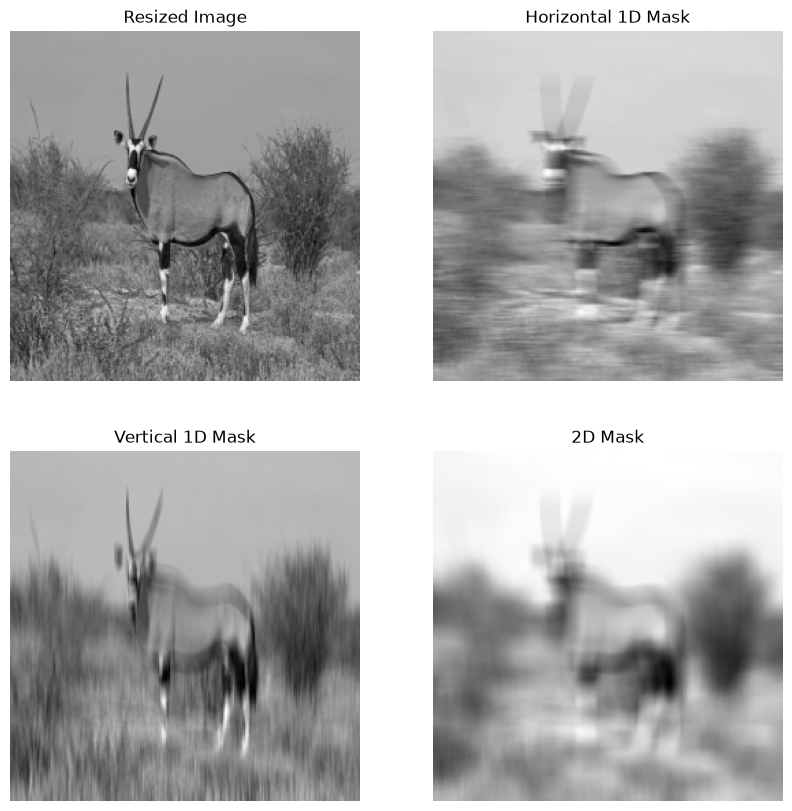

In [7]:
#your solution
# Show all the images in a 2x2 grid
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

# Display the original image
ax[0, 0].imshow(oryx_gray, cmap="gray")
# Remove the ticks and axes
ax[0, 0].axis("off")
# Add a title to the image
ax[0, 0].set_title("Resized Image")

# Display the horizontal 1D mask
ax[0, 1].imshow(oryx_h1d, cmap="gray")
# Remove the ticks and axes
ax[0, 1].axis("off")
# Add a title to the image
ax[0, 1].set_title("Horizontal 1D Mask")

# Display the vertical 1D mask
ax[1, 0].imshow(oryx_v1d, cmap="gray")
# Remove the ticks and axes
ax[1, 0].axis("off")
# Add a title to the image
ax[1, 0].set_title("Vertical 1D Mask")

# Display the 2D mask
ax[1, 1].imshow(oryx_2d, cmap="gray")
# Remove the ticks and axes
ax[1, 1].axis("off")
# Add a title to the image
ax[1, 1].set_title("2D Mask")

plt.show()

### Effect of the Convolution Masks

> **1D Horizontal and Vertical Masks:**
These masks smooth the image in only one direction—horizontally or vertically. This produces directional blurring while preserving more details in the perpendicular direction. As a result, the pixel intensity range is moderately reduced.

> **2D Mask:**
This mask smooths the image in both horizontal and vertical directions simultaneously, producing a stronger overall blurring effect. Because it averages a larger neighborhood of pixels, it generally reduces the pixel intensity range more significantly.


**c) RGB Image Convolution with a 2D Filter**

- Implement a function called `conv_coor(image, mask)` that applies the same 2D filter independently to each of the three RGB channels.

- Resize the original `oryx.png` image to **256 × 256 pixels**, and test your function using a **7 × 7 uniform mask**.

- Visualize the result and compare the filtered RGB image with the original image.

> Expected output is illustrated below:

<img src="images_notebook/rgb_filtered.jpg">


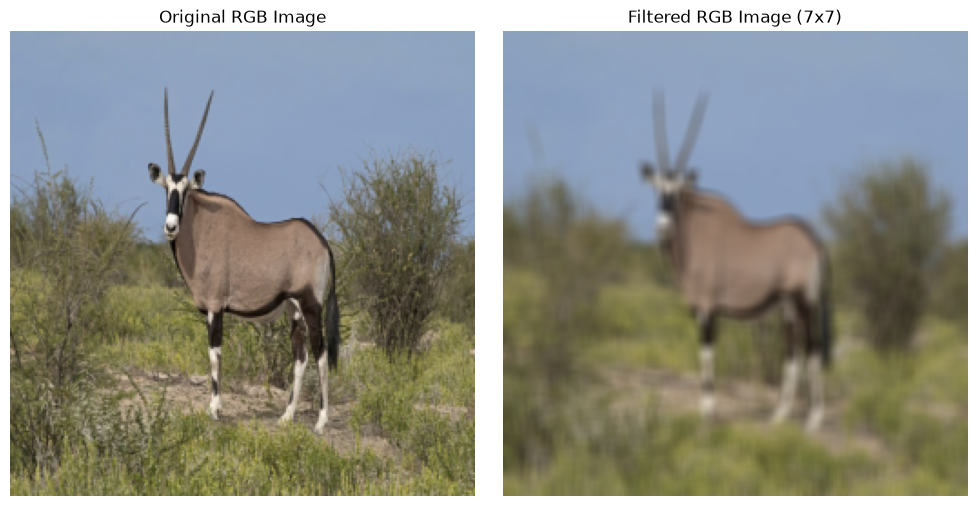

In [8]:
# your solution

# Define a function to apply a 2D convolution mask
# independently to each RGB channel.
def conv_coor(image, mask):

    # Create an empty image with the same dimensions as the input.
    # Use float type to preserve the decimal values produced by convolution.
    result_image = np.zeros_like(image, dtype=float)

    # Normalize the mask so that all mask values sum to 1.
    mask = mask / np.sum(mask)

    # Apply the mask separately to the Red, Green, and Blue channels.
    for i in range(3):
        result_image[:, :, i] = convolve(image[:, :, i], mask)

    # Return the filtered RGB image.
    return result_image


# Create a 7x7 uniform mask.
mask_3d = np.ones((7, 7))

# Convert the image to floating-point values and apply the 7x7 filter.
oryx_3d = conv_coor(img_as_float(oryx_resized), mask_3d)


# Create a figure to compare the original and filtered images.
plt.figure(figsize=(10, 5))

# Display the original RGB image.
plt.subplot(1, 2, 1)
plt.imshow(img_as_float(oryx_resized))
plt.title("Original RGB Image")
plt.axis("off")

# Display the filtered RGB image.
plt.subplot(1, 2, 2)
plt.imshow(oryx_3d)
plt.title("Filtered RGB Image (7x7)")
plt.axis("off")

# Adjust the layout and display the figure.
plt.tight_layout()
plt.show()


## **2.3 Effect of image scale on convolutions**

**a)** Image Rescaling and Histogram Analysis

Resize the grayscale image `oryx_gray` and observe how the image histogram changes.

1. **Reduce** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
2. **Enlarge** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
3. Display the histograms of the original, reduced, and enlarged images side by side and compare them.

**Question:**
Are there any differences between the histograms? Explain what happens and why the histogram may change after rescaling the image.

> Expected output is illustrated below:

<img src="images_notebook/resize_impact.jpg">


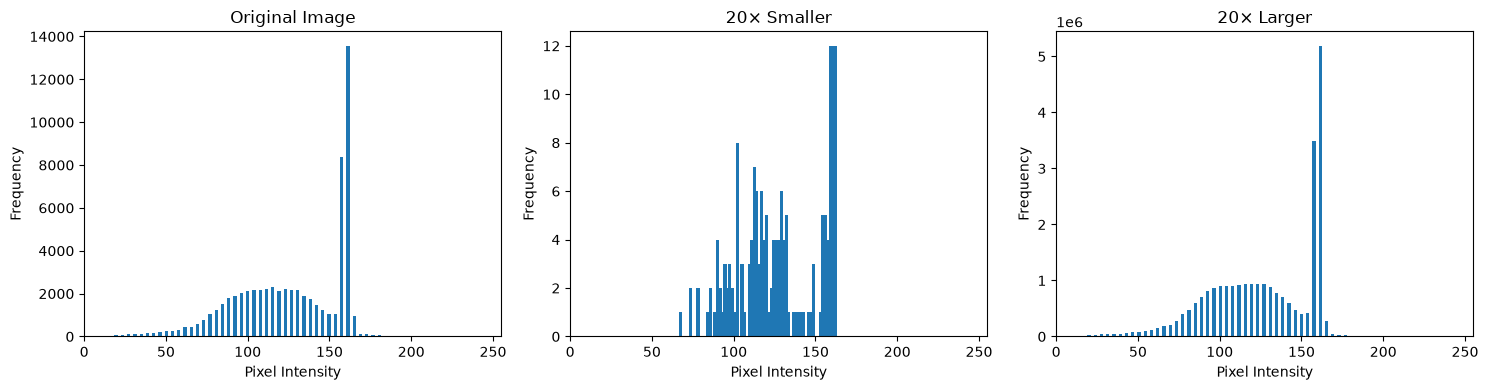

In [10]:
# your solution

from skimage.transform import rescale

# Create a figure with three plots arranged side by side.
plt.figure(figsize=(15, 4))


# ---------------------------------------------------------
# 1. Histogram of the original grayscale image
# ---------------------------------------------------------

# Compute the histogram of the original image.
hist, bins = exposure.histogram(oryx_gray, nbins=64)

# Plot the histogram.
plt.subplot(1, 3, 1)
plt.bar(255 * bins, hist, width=2)
plt.title("Original Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])


# ---------------------------------------------------------
# 2. Histogram of the image rescaled 20× smaller
# ---------------------------------------------------------

# Rescale the image to make it 20 times smaller.
oryx_rescaled = rescale(oryx_gray, 1 / 20)

# Compute the histogram of the rescaled image.
hist, bins = exposure.histogram(oryx_rescaled, nbins=64)

# Plot the histogram.
plt.subplot(1, 3, 2)
plt.bar(255 * bins, hist, width=2)
plt.title("20× Smaller")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])


# ---------------------------------------------------------
# 3. Histogram of the image rescaled 20× larger
# ---------------------------------------------------------

# Rescale the image to make it 20 times larger.
oryx_rescaled = rescale(oryx_gray, 20)

# Compute the histogram of the enlarged image.
hist, bins = exposure.histogram(oryx_rescaled, nbins=64)

# Plot the histogram.
plt.subplot(1, 3, 3)
plt.bar(255 * bins, hist, width=2)
plt.title("20× Larger")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])


# Adjust spacing between the plots and display the figure.
plt.tight_layout()
plt.show()


**Explanation**

The histogram of the original image (oryx_gray) shows the distribution of pixel intensities across 64 bins. The image's pixel values range from 0 (black) to 255 (white), with most values concentrated in the mid-intensity range.

When we reduce the image size by 20 times, the histogram becomes sparse. This is expected, as downsampling results in a significant loss of detail. Many neighboring pixel intensities are merged or averaged, leading to fewer distinct intensity values. The reduction in pixel resolution also causes lower overall pixel counts in the histogram. This explains why the histogram peaks are shorter and less defined than those of the original image.

Upsampling the image by 20 times results in a histogram that retains the shape of the original histogram, but with significantly higher pixel counts in each bin. This occurs because the upsampling process involves interpolating new pixels based on neighboring values, which increases the total number of pixels while preserving the original intensity distribution. Upsampling increases the number of pixels but does not introduce new intensity levels.

**b) Convolution and Histogram Analysis**

Apply a **7 × 7 uniform convolution mask** to the images from the previous exercise, compute their histograms, and compare the results.

1. **Plot the original `oryx_gray` image and its histogram** for reference.

2. Convolve the original `oryx_gray` image and compute its histogram.

3. Convolve the **reduced `oryx_gray` image from the previous exercise** and compute its histogram.

4. Convolve the **enlarged `oryx_gray` image from the previous exercise** and compute its histogram.

**Note:** Display the images in the **top row** and their corresponding histograms in the **bottom row**, using `nbins = 32`.

**Question:**
Compare the original and filtered images and their histograms. What differences do you observe, and why do these differences occur?

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered2.jpg">

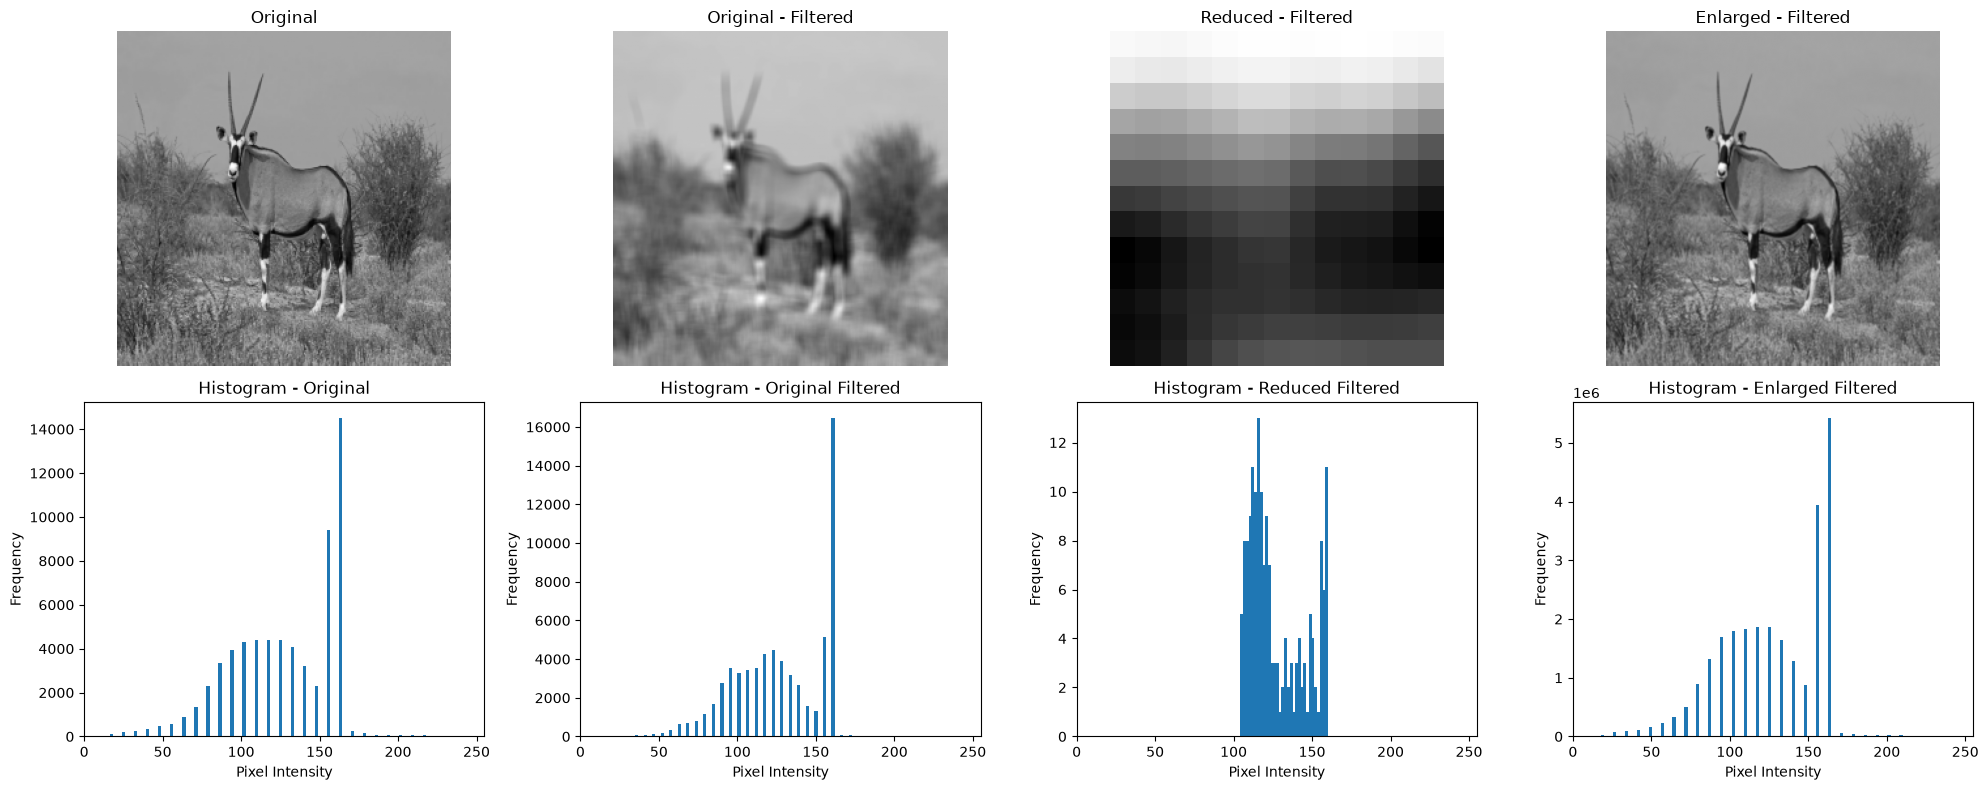

In [10]:
# your solution

# Create a 7x7 uniform convolution mask.
mask = np.ones((7, 7))

# Normalize the mask so that all values sum to 1.
mask = mask / np.sum(mask)


# ---------------------------------------------------------
# Prepare the images
# ---------------------------------------------------------

# Original grayscale image.
oryx_original = img_as_float(oryx_gray)

# Reduced and enlarged images from the previous exercise.
oryx_small = rescale(oryx_original, 1 / 20)
oryx_big = rescale(oryx_original, 20)


# ---------------------------------------------------------
# Apply the 7x7 convolution mask
# ---------------------------------------------------------

# Filter the original, reduced, and enlarged images.
oryx_blurred = convolve(oryx_original, mask)
oryx_small_blurred = convolve(oryx_small, mask)
oryx_big_blurred = convolve(oryx_big, mask)


# ---------------------------------------------------------
# Compute histograms
# ---------------------------------------------------------

# Histogram of the original image.
hist_original, bins_original = exposure.histogram(
    oryx_original, nbins=32
)

# Histogram of the filtered original image.
hist, bins = exposure.histogram(
    oryx_blurred, nbins=32
)

# Histogram of the filtered reduced image.
hist_small, bins_small = exposure.histogram(
    oryx_small_blurred, nbins=32
)

# Histogram of the filtered enlarged image.
hist_big, bins_big = exposure.histogram(
    oryx_big_blurred, nbins=32
)


# ---------------------------------------------------------
# Display images and histograms
# ---------------------------------------------------------

# Create a figure with two rows and four columns.
# The top row shows the images.
# The bottom row shows their corresponding histograms.
plt.figure(figsize=(20, 8))


# ---------------------------------------------------------
# Top row: images
# ---------------------------------------------------------

# 1. Original grayscale image.
plt.subplot(2, 4, 1)
plt.imshow(oryx_original, cmap="gray")
plt.title("Original")
plt.axis("off")

# 2. Original image after convolution.
plt.subplot(2, 4, 2)
plt.imshow(oryx_blurred, cmap="gray")
plt.title("Original - Filtered")
plt.axis("off")

# 3. Reduced image after convolution.
plt.subplot(2, 4, 3)
plt.imshow(oryx_small_blurred, cmap="gray")
plt.title("Reduced - Filtered")
plt.axis("off")

# 4. Enlarged image after convolution.
plt.subplot(2, 4, 4)
plt.imshow(oryx_big_blurred, cmap="gray")
plt.title("Enlarged - Filtered")
plt.axis("off")


# ---------------------------------------------------------
# Bottom row: histograms
# ---------------------------------------------------------

# 1. Histogram of the original image.
plt.subplot(2, 4, 5)
plt.bar(255 * bins_original, hist_original, width=2)
plt.title("Histogram - Original")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])

# 2. Histogram of the filtered original image.
plt.subplot(2, 4, 6)
plt.bar(255 * bins, hist, width=2)
plt.title("Histogram - Original Filtered")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])

# 3. Histogram of the filtered reduced image.
plt.subplot(2, 4, 7)
plt.bar(255 * bins_small, hist_small, width=2)
plt.title("Histogram - Reduced Filtered")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])

# 4. Histogram of the filtered enlarged image.
plt.subplot(2, 4, 8)
plt.bar(255 * bins_big, hist_big, width=2)
plt.title("Histogram - Enlarged Filtered")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])


# Adjust the spacing between plots and display the figure.
plt.tight_layout()
plt.show()


**Explanation**

After applying a uniform 7×7 convolution mask, the image is blurred, meaning the high-frequency details (such as edges and sharp transitions) are smoothed out. This causes the intensity values in the image to become more similar across neighboring pixels, which reduces the variance in the pixel intensities. As a result, the histogram of the convolved image shows a more pronounced peak in the mid-intensity range, as the blurring reduces intensity variation.


The downsampled image has fewer pixels, so the resulting histogram is more sparse, with fewer distinct intensity values. After convolution, the histogram shows a reduced range of intensities, and there are fewer unique bins. This is because the downsampled image has already lost a significant amount of detail, so convolution has less of an effect. The histogram is more clustered, reflecting the loss of intensity diversity due to both downsampling and blurring. For example, values below 100 are now lost.

The upsampled image contains many more pixels than the original. The resulting histogram (after convolution) closely resembles the original but on a much larger scale, with very high bin counts. The peaks are similar in shape to the original, but because the image contains many more pixels, the bin counts are much higher. The convolution smooths high-frequency details in the upsampled image, creating a blurring effect, but the intensity range does not become more uniform compared to the original. The distribution of intensities remains similar to that of the original image, with the smoothing mainly reducing variations in pixel intensity.

## **2.4 Image processing with weighting and non-linear filters**

**a) Generate the following kernels and apply them to the `oryx_gray` image:**

1. Generate a Gaussian kernel with σ = 1 and apply it to the image.
2. Generate Gaussian kernels with three different σ values (0.5, 2, and 3) and apply them to the image. Which σ value is the most appropriate for preserving the main objects and structures in the image?
3. Apply a median filter using different mask shapes: disk, rectangle, and diamond. Apply the median filter using different mask sizes for each shape: `disk(5)`, `rectangle(5,20)`, and `diamond(3)`, and compare their effects on the original image. What is the effect of using the different mask shapes on the original image?

> **Note:** For the disk and diamond filters, the specified value represents the **radius in pixels**, while `morphology.rectangle(5, 20)` specifies the **height and width of the rectangular structuring element (5 × 20 pixels)**.


Comment on the effects of the different filters on the original image.

**Hint:** 
- Search for the [skimage.filters function](https://scikit-image.org/docs/stable/api/skimage.filters.html) for creating the different filters.
- Also check [scikit-image — skimage.morphology documentation](https://scikit-image.org/docs/stable/api/skimage.morphology)

> Expected output is illustrated below:

<img src="images_notebook/filter.jpg">


/var/folders/qc/t_v_crls4f118nczny427fq40000gn/T/ipykernel_85585/193858941.py:19: FutureWarning: `rectangle` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  median_rectangle = median(oryx_gray_float, morphology.rectangle(5, 20))


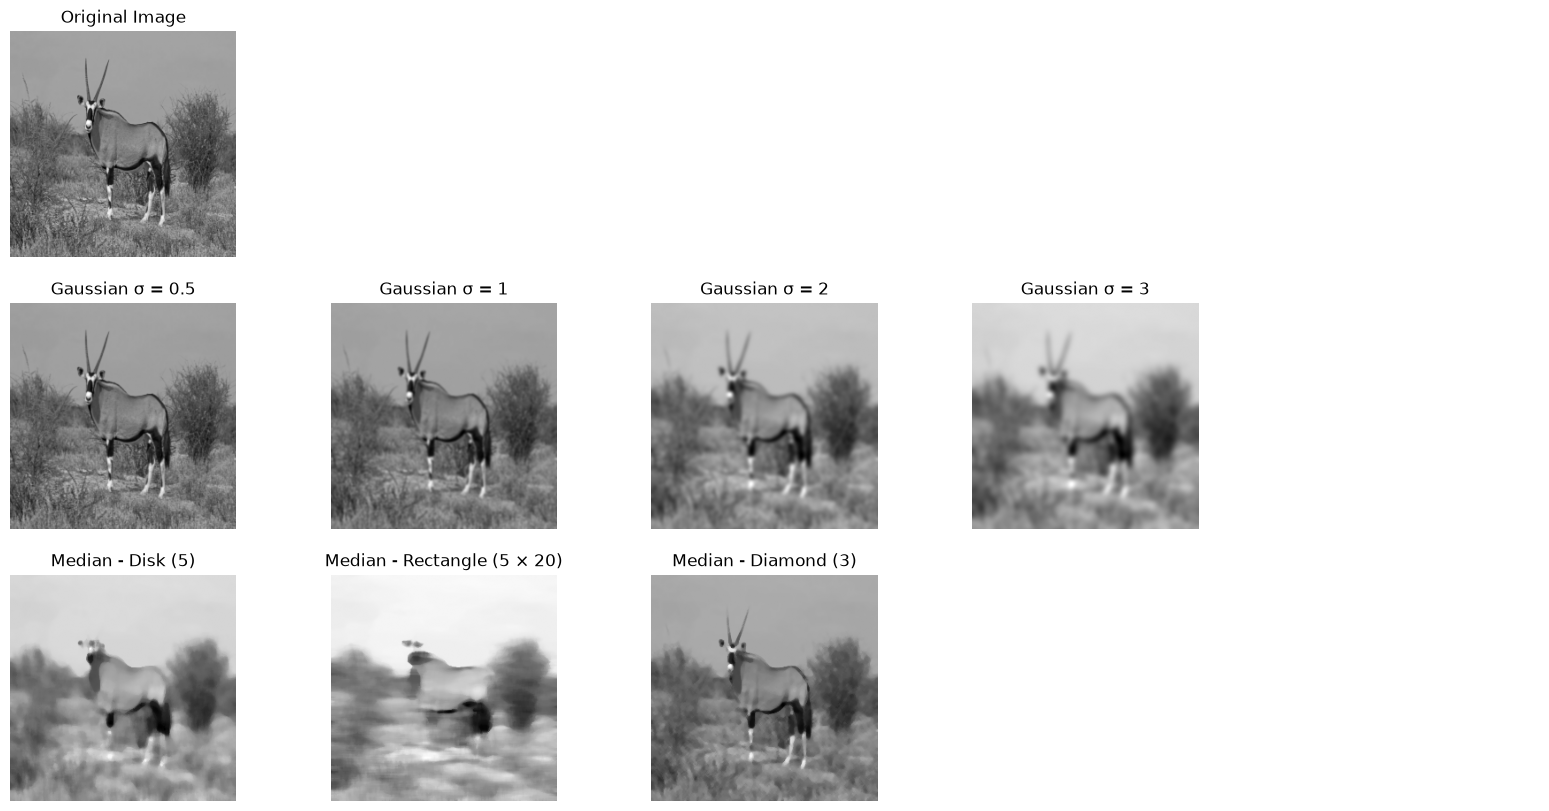

In [11]:
from skimage import filters, img_as_float, morphology
from skimage.filters import gaussian, median
from skimage.morphology import disk, rectangle, diamond
import matplotlib.pyplot as plt

# Convert image to float for better processing
oryx_gray_float = img_as_float(oryx_gray)

# 1. Apply Gaussian filter with sigma = 1
gaussian_sigma_1 = gaussian(oryx_gray_float, sigma=1)

# 2. Apply Gaussian filter with three different sigma values
gaussian_sigma_0_5 = gaussian(oryx_gray_float, sigma=0.5)
gaussian_sigma_2 = gaussian(oryx_gray_float, sigma=2)
gaussian_sigma_3 = gaussian(oryx_gray_float, sigma=3)

# 3. Apply median filters with different mask shapes
median_disk = median(oryx_gray_float, morphology.disk(5))
median_rectangle = median(oryx_gray_float, morphology.rectangle(5, 20))
median_diamond = median(oryx_gray_float, morphology.diamond(3))

# Plot results
fig, ax = plt.subplots(3, 5, figsize=(20, 10))

# ---------------------------------------------------------
# Row 0: Original image
# ---------------------------------------------------------

ax[0, 0].imshow(oryx_gray_float, cmap='gray')
ax[0, 0].set_title('Original Image')
ax[0, 0].axis('off')

# Leave remaining spaces empty
for i in range(1, 5):
    ax[0, i].axis('off')


# ---------------------------------------------------------
# Row 1: Gaussian filters
# ---------------------------------------------------------

ax[1, 0].imshow(gaussian_sigma_0_5, cmap='gray')
ax[1, 0].set_title('Gaussian σ = 0.5')
ax[1, 0].axis('off')

ax[1, 1].imshow(gaussian_sigma_1, cmap='gray')
ax[1, 1].set_title('Gaussian σ = 1')
ax[1, 1].axis('off')

ax[1, 2].imshow(gaussian_sigma_2, cmap='gray')
ax[1, 2].set_title('Gaussian σ = 2')
ax[1, 2].axis('off')

ax[1, 3].imshow(gaussian_sigma_3, cmap='gray')
ax[1, 3].set_title('Gaussian σ = 3')
ax[1, 3].axis('off')

ax[1, 4].axis('off')


# ---------------------------------------------------------
# Row 2: Median filters
# ---------------------------------------------------------

ax[2, 0].imshow(median_disk, cmap='gray')
ax[2, 0].set_title('Median - Disk (5)')
ax[2, 0].axis('off')

ax[2, 1].imshow(median_rectangle, cmap='gray')
ax[2, 1].set_title('Median - Rectangle (5 × 20)')
ax[2, 1].axis('off')

ax[2, 2].imshow(median_diamond, cmap='gray')
ax[2, 2].set_title('Median - Diamond (3)')
ax[2, 2].axis('off')

ax[2, 3].axis('off')
ax[2, 4].axis('off')

plt.show()

### Discussion

1. **Gaussian Kernel with Different Sigma Values**:

- **Gaussian (Sigma = 0.5)**:
  The minimal smoothing effect from this filter preserves the finer details of the image, including the oryx's horns. The image retains its overall sharpness, with only slight noise reduction. The background vegetation and edges remain clear.
- **Gaussian (Sigma = 1)**:
  This filter introduces a moderate smoothing effect. While the image remains reasonably sharp, some fine details, such as the texture of the oryx’s fur, are slightly blurred. However, the main structures, including the horns, are still preserved, making this an appropriate balance between noise reduction and detail retention.
- **Gaussian (Sigma = 2)**:
  With a higher sigma, the smoothing effect becomes more prominent, and fine details like the oryx's horns start to blur. The edges of the horns are less distinct, and much of the texture of the fur and background is lost. The image remains smooth but starts to lose important features.
- **Gaussian (Sigma = 3)**:
  This level of blurring is excessive for preserving fine details. The oryx’s horns and other small features are almost completely lost, blending into the background. The image appears overly smoothed, with large structures (like the oryx's body) being the only distinguishable features.



2. **Median Filters with Different Mask Shapes**:

- **Median (Disk Shape)**:
  The disk-shaped median filter effectively removes noise while maintaining some of the larger structures. However, **the fine details of the oryx’s horns are lost** in this filter. The disk shape smooths out the sharpness around small, thin features like the horns, making them blend with the sky. This is a downside of using a disk-shaped filter when trying to preserve very thin structures. A smaller disk would preserve more fine details but would provide less noise reduction.
- **Median (Rectangle Shape)**:
  The rectangular-shaped median filter introduces even more pronounced distortions. Not only do **the horns of the oryx disappear**, but the rectangular shape also stretches and distorts the vertical and horizontal features of the image. The overall structure of the oryx is preserved, but the fine details, especially the horns, are heavily smoothed out. The larger mask size increases the filtering effect but reduces the preservation of small structures. Therefore, this filter is less suitable when preserving fine details is important.
- **Median (Diamond Shape)**:
  The diamond-shaped median filter provides the best balance among the median filters. While there is some loss of detail, especially around the horns, they remain more visible compared to the disk and rectangle filters. This filter effectively reduces noise while retaining more of the original structure, especially in small features like the horns and edges of the oryx.

  > Overall, the size and shape of the median filter have a significant effect on the result. Larger masks generally provide stronger noise reduction but also remove more fine details. In this example, the larger rectangular mask (5 × 20) produces the greatest loss of detail, while the smaller diamond mask (3) preserves more of the original image structure.



### Summary of Filter Effects:

- **Gaussian Filters**: Gaussian filters provide progressive blurring based on the sigma value. With **sigma = 0.5**, the horns and fine details are well-preserved. As the sigma increases, the smoothing effect causes more detail loss, particularly with sigma values of 2 and 3, where the horns and other fine structures are blurred out.
- **Median Filters**: Median filters generally preserve edges better than Gaussian filters, but different mask shapes and sizes affect the result. The **disk-shaped** and **rectangle-shaped filters** lead to a loss of the oryx’s horns and other fine features. The **diamond-shaped filter**, while still causing some smoothing, does a better job of preserving the horns and other important structures compared to the other median filter shapes.

b) **(Optional)** Apply the smoothing on some other images and present their results.

In [12]:
#your solution

### **2.5 Comparison of Edge Detection Techniques**

**a)** Load the 'logo_pozo.jpg' image and visualize its contours.

<img src="images_notebook/logo_pozo.jpg" width="200" height="200">

First, convert it to gray scale. Then, apply the different contour extraction tecniques introduced during the theory session and change any parameter if necessary for detecting the edges of the image:

1. Prewitt
2. Sobel
3. Canny

Use subplot and title to visualize the results.

#### **Questions**

* What are the optimal parameter values for each method?
* Is it necessary to normalize the masks, as is commonly done when applying smoothing filters? Explain your answer.

**Hint:** Use `skimage.feature.canny` for the Canny edge detector and `skimage.filters` for the Prewitt and Sobel operators.

> Expected output is illustrated below:

<img src="images_notebook/edge.jpg">


> **Note:** Prewitt and Sobel produce grayscale images because they measure edge strength (gradient magnitude), whereas Canny applies thresholding to generate a binary image containing only the detected edges.



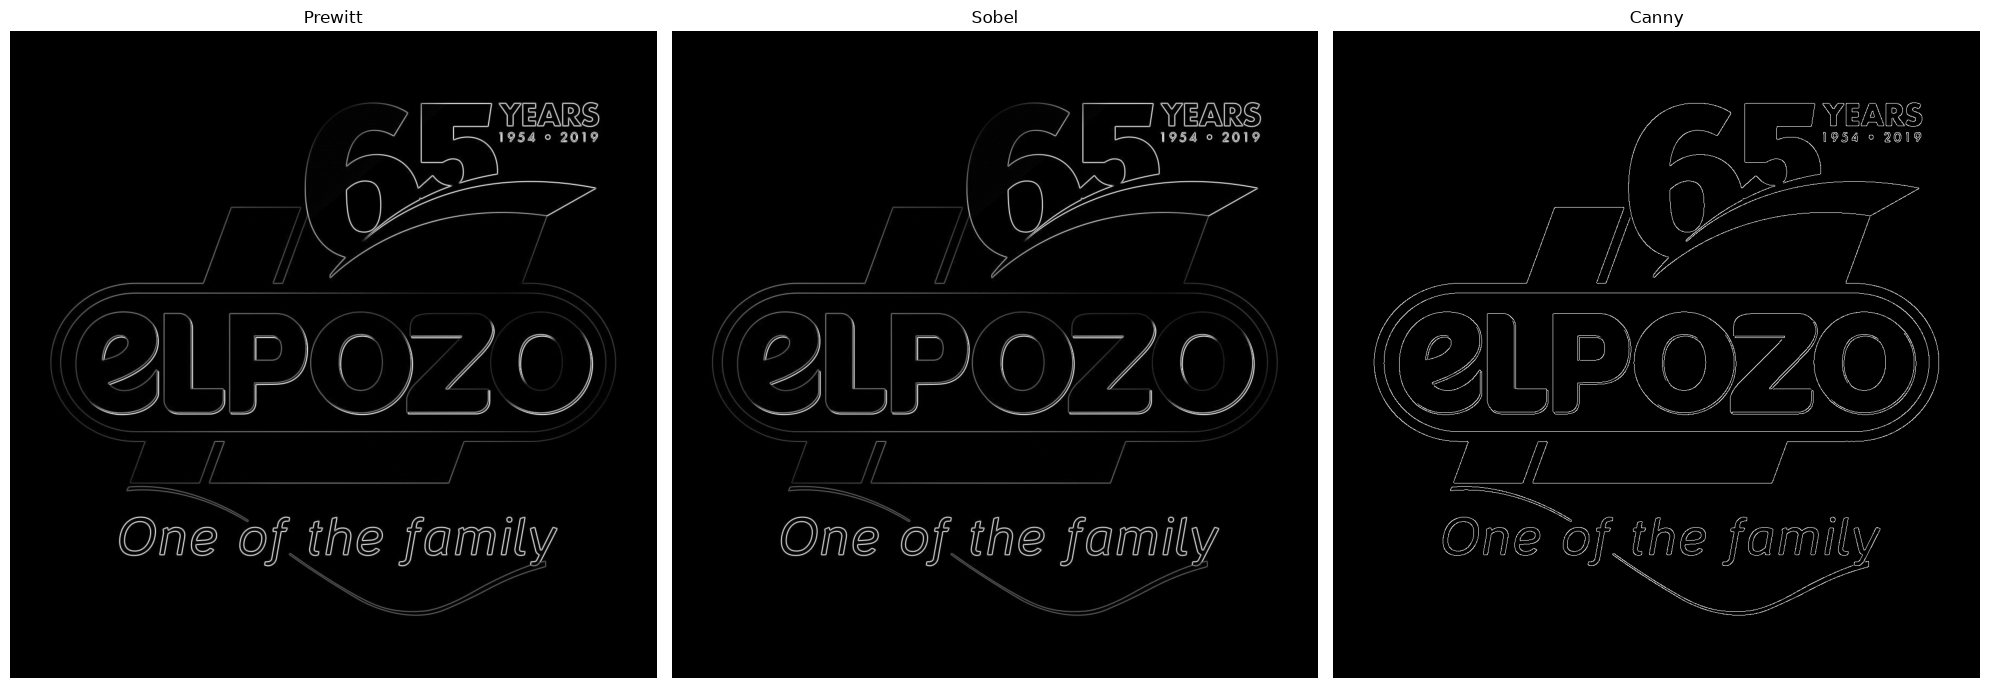

In [13]:
import warnings
warnings.filterwarnings("ignore")

# Edge detection methods
from skimage.feature import canny
from skimage.filters import sobel, prewitt

# Load the image
logo = io.imread("images_notebook/logo_pozo.jpg")

# Convert the RGB image to grayscale
logo_gray = rgb2gray(logo[:, :, :3])

# Apply different edge detection techniques
logo_pre = prewitt(logo_gray)      # Prewitt operator
logo_sob = sobel(logo_gray)        # Sobel operator
logo_canny = canny(logo_gray)      # Canny edge detector

# Display the detected contours
fig, ax = plt.subplots(1, 3, figsize=(20, 7))

# Prewitt edge detection
ax[0].imshow(logo_pre, cmap="gray")
ax[0].axis("off")
ax[0].set_title("Prewitt")

# Sobel edge detection
ax[1].imshow(logo_sob, cmap="gray")
ax[1].axis("off")
ax[1].set_title("Sobel")

# Canny edge detection
ax[2].imshow(logo_canny, cmap="gray")
ax[2].axis("off")
ax[2].set_title("Canny")

plt.tight_layout()
plt.show()

### Discussion

- What are the optimal parameter values for each method?

For Prewitt and Sobel, the default parameters were sufficient and no tuning was required. For Canny, the default parameter values provided the best balance between edge detection and noise suppression for this image.

- Is it necessary to normalize the masks, as is commonly done when applying smoothing filters?


No, it is not necessary to normalize the mask for edge detection filters like Prewitt, Sobel, or Canny. These filters are based on gradient calculations rather than averaging pixel values like in smoothing operations, so normalization of the mask is not required.

**b)**	Repeat the experiment with other images, you can use the ones included in the folder **images** (`cr.jpg` and `messi.jpg`). 
- Comment if some parameter needs to be changed for the different images.

#### **Questions**

- Does applying smoothing before edge detection improve the detected contours?
- What are the limitations of the different edge detection methods?

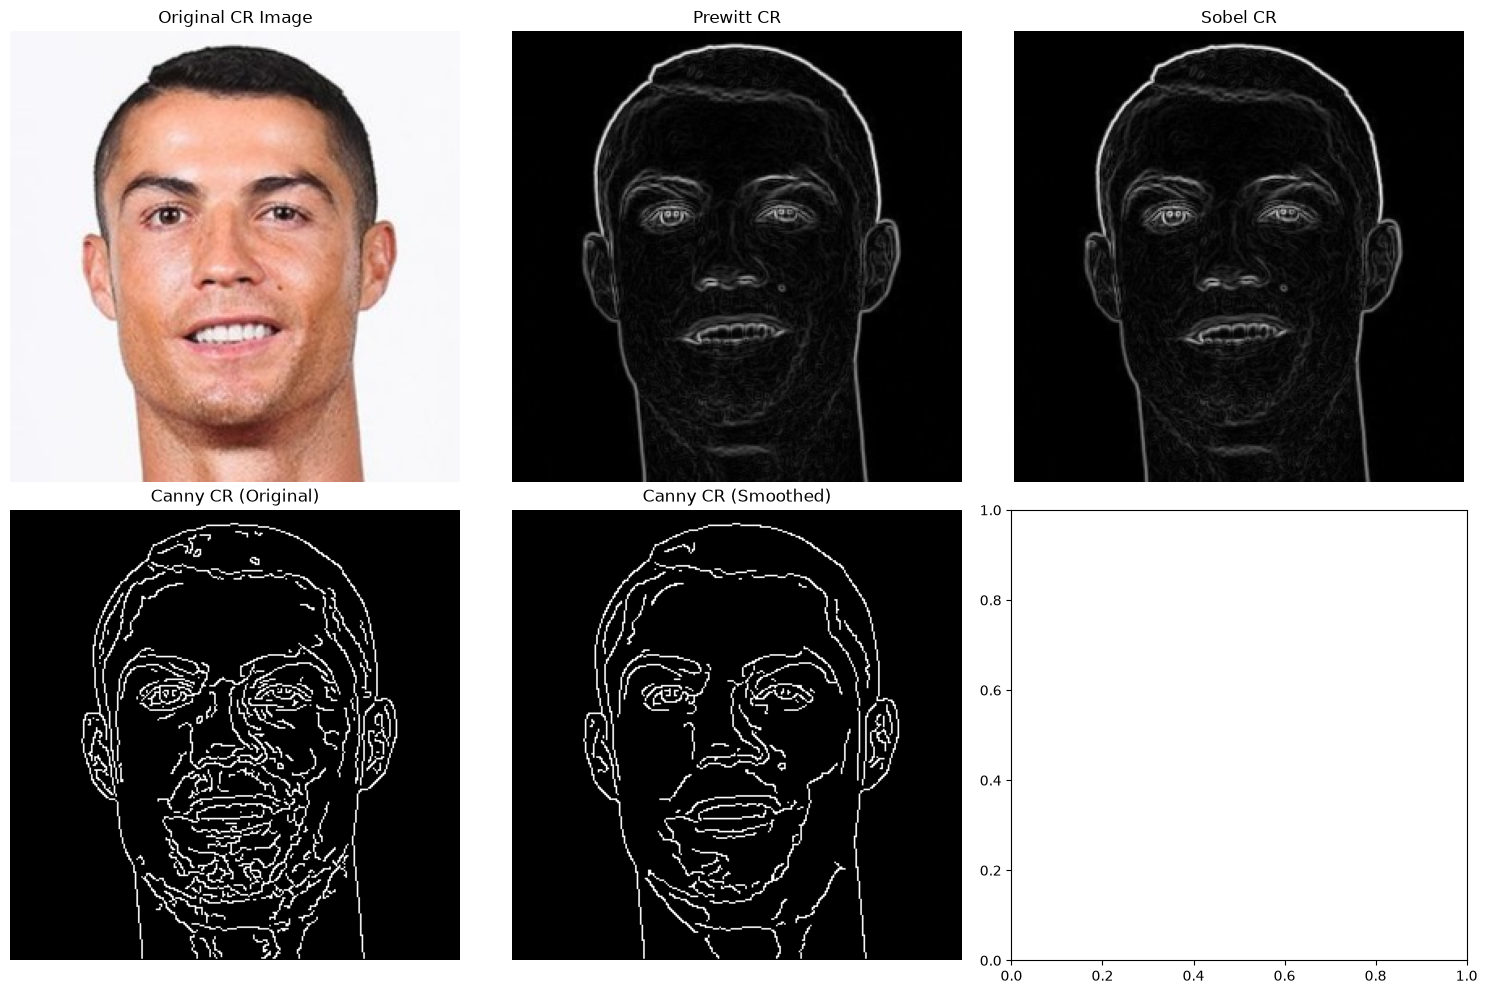

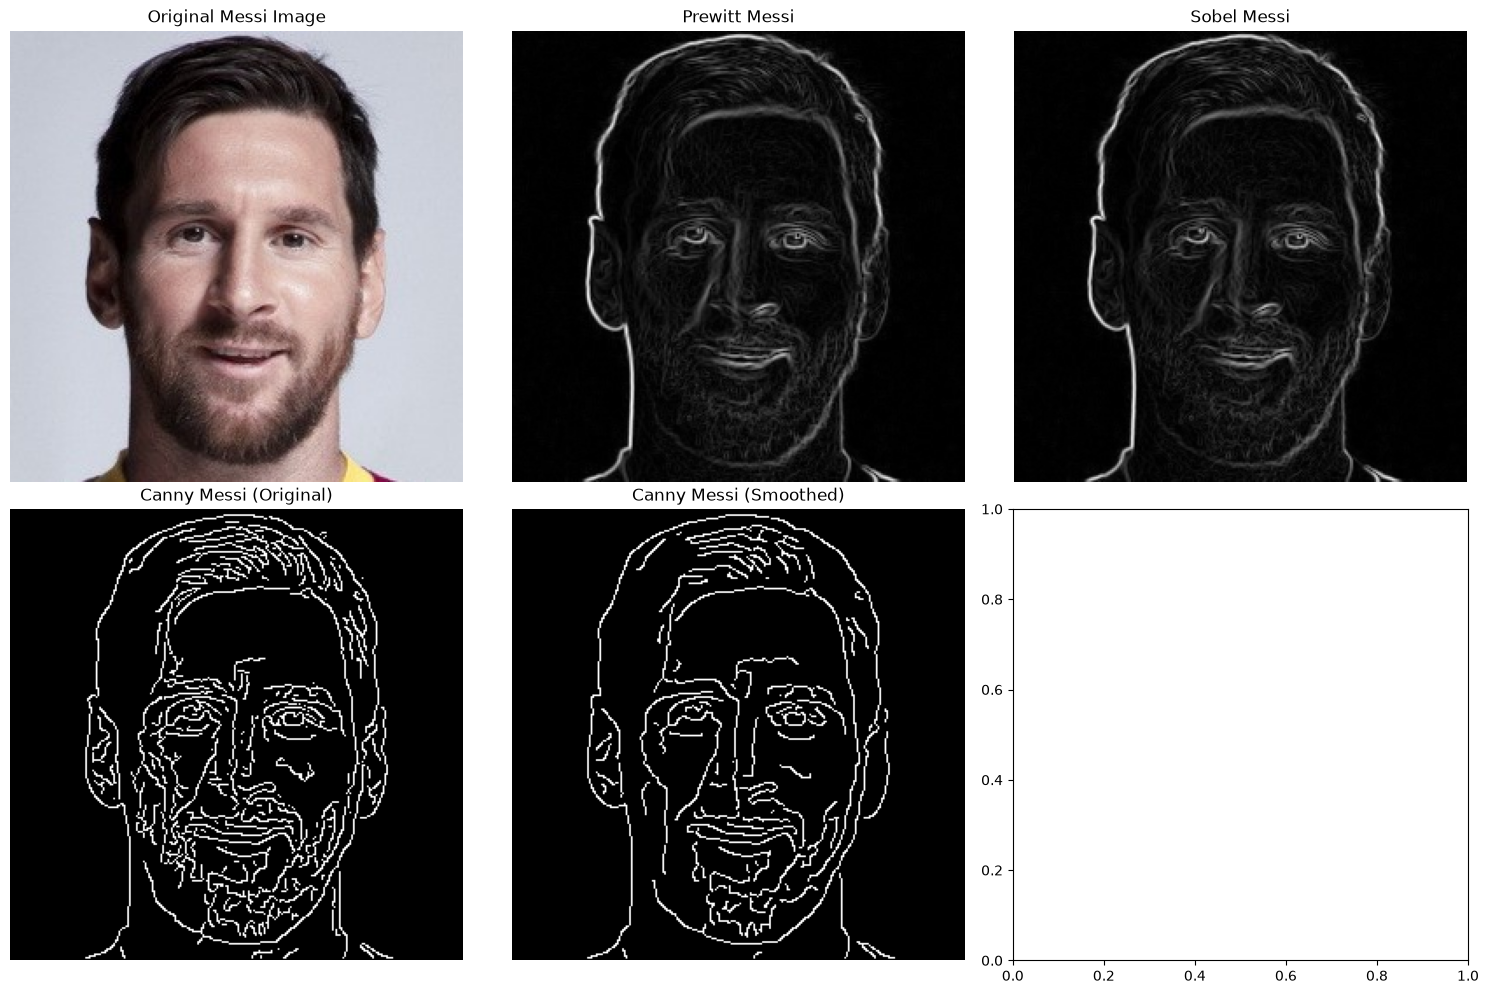

In [14]:
#your solution
# Load images cr.jpg and messi.jpg
image_cr_path = "images_notebook/cr.jpg"
image_messi_path = "images_notebook/messi.jpg"

# Load and convert to grayscale
image_cr = io.imread(image_cr_path)
image_cr_gray = rgb2gray(image_cr)

image_messi = io.imread(image_messi_path)
image_messi_gray = rgb2gray(image_messi)

# Apply Gaussian smoothing (with sigma=1) before edge detection
image_cr_smoothed = gaussian(image_cr_gray, sigma=1)
image_messi_smoothed = gaussian(image_messi_gray, sigma=1)

# Apply Prewitt filter
prewitt_cr = prewitt(image_cr_gray)
prewitt_messi = prewitt(image_messi_gray)

# Apply Sobel filter
sobel_cr = sobel(image_cr_gray)
sobel_messi = sobel(image_messi_gray)

# Apply Canny filter
canny_cr = canny(image_cr_gray, sigma=1)
canny_messi = canny(image_messi_gray, sigma=1)

# Apply edge detection on the smoothed images
canny_cr_smoothed = canny(image_cr_smoothed, sigma=1)
canny_messi_smoothed = canny(image_messi_smoothed, sigma=1)

# Plot results for CR image
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0, 0].imshow(image_cr, cmap='gray')
ax[0, 0].set_title("Original CR Image")
ax[0, 0].axis('off')

ax[0, 1].imshow(prewitt_cr, cmap='gray')
ax[0, 1].set_title("Prewitt CR")
ax[0, 1].axis('off')

ax[0, 2].imshow(sobel_cr, cmap='gray')
ax[0, 2].set_title("Sobel CR")
ax[0, 2].axis('off')

ax[1, 0].imshow(canny_cr, cmap='gray')
ax[1, 0].set_title("Canny CR (Original)")
ax[1, 0].axis('off')

ax[1, 1].imshow(canny_cr_smoothed, cmap='gray')
ax[1, 1].set_title("Canny CR (Smoothed)")
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

# Plot results for Messi image
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0, 0].imshow(image_messi, cmap='gray')
ax[0, 0].set_title("Original Messi Image")
ax[0, 0].axis('off')

ax[0, 1].imshow(prewitt_messi, cmap='gray')
ax[0, 1].set_title("Prewitt Messi")
ax[0, 1].axis('off')

ax[0, 2].imshow(sobel_messi, cmap='gray')
ax[0, 2].set_title("Sobel Messi")
ax[0, 2].axis('off')

ax[1, 0].imshow(canny_messi, cmap='gray')
ax[1, 0].set_title("Canny Messi (Original)")
ax[1, 0].axis('off')

ax[1, 1].imshow(canny_messi_smoothed, cmap='gray')
ax[1, 1].set_title("Canny Messi (Smoothed)")
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Discussion

**1. Does applying smoothing before edge detection improve the detected contours?**

- Yes, in many cases smoothing the image before edge detection improves the contours by reducing noise and small intensity variations that can generate false edges. However, excessive smoothing may blur object boundaries and remove fine details, resulting in less accurate contour detection. Also note that the Canny detector already includes a Gaussian smoothing step, which helps reduce noise before extracting edges.

**2. What are the limitations of the different edge detection methods?**

- **Prewitt** and **Sobel** are sensitive to noise and often produce thick, blurry edges because they only measure intensity gradients and do not apply thresholding automatically. As a result, they return grayscale edge-strength images, requiring an additional thresholding step to obtain a binary contour map. These gradient-based filters perform well at detecting large-scale edges but lack precision when it comes to fine details. These methods may struggle with images that have a lot of texture or fine details, leading to noisy or incomplete edges. They also do not include noise reduction steps, so they may detect unnecessary edges, especially in regions with subtle gradients, such as skin texture or beard hair. 

- **Canny**, on the other hand, includes thresholding and edge thinning, producing cleaner and more precise contours. However, its performance depends on the choice of parameters, and excessive smoothing may remove fine details or weak edges. Nevertheless, while the Canny filter is much better at detecting fine details and producing clean edges, it is **sensitive to noise**. Without pre-smoothing, the Canny filter can picks up extra edges related to noise and texture.

**c)** Implement the Sobel and Prewitt edge detection operators manually using the `convolve` function instead of the implementations provided by `skimage.filters`.

- Define the corresponding horizontal and vertical kernels for each operator, apply them to the image using convolution, and compute the gradient magnitude from the resulting responses.

- Visualize the results and compare them with those obtained using `skimage.filters.sobel` and `skimage.filters.prewitt`.

> Expected output is illustrated below:

<img src="images_notebook/implemented_detectors.jpg">

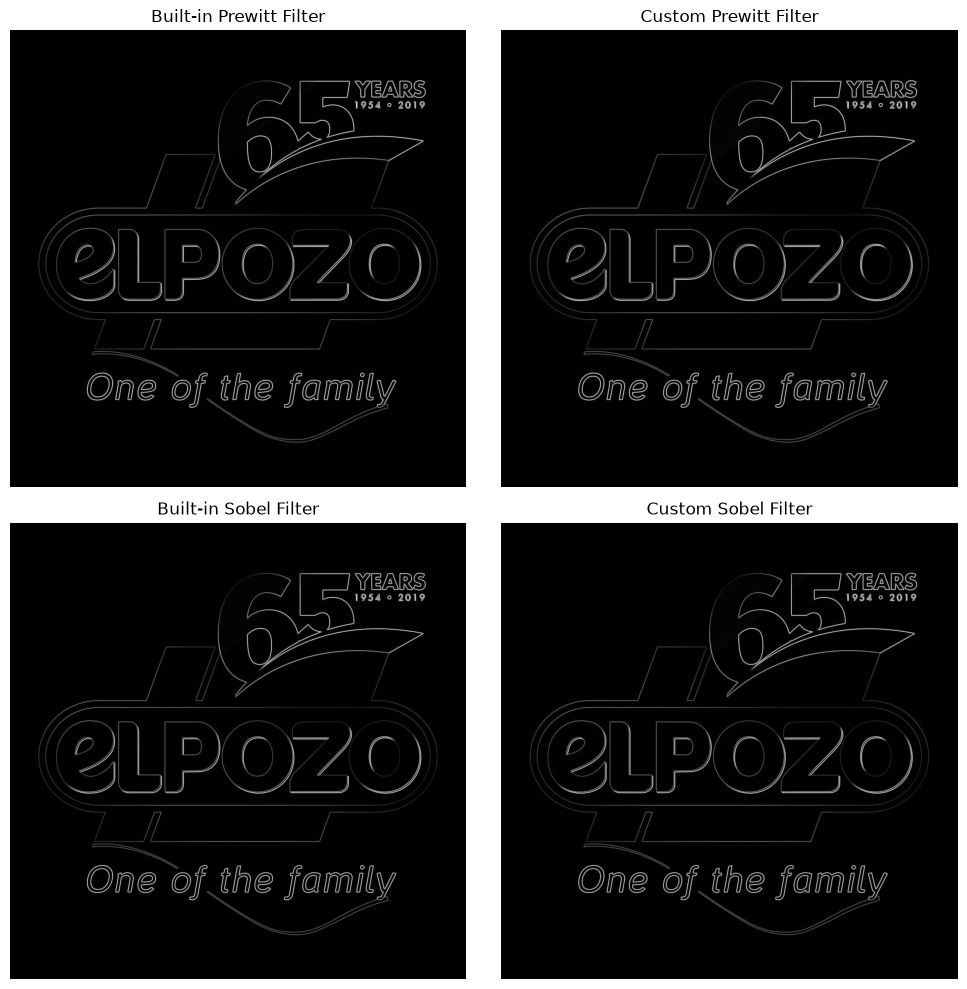

In [15]:
#your solution

from skimage.util import img_as_ubyte

def detect_edges(img, filter_x, filter_y, filters_normalized = False):
    """
    Params:
        img: The image where the edges will be detected. It needs to be uint8
            and in the range of [0, 255]
        filter_x: the filter used to detect vertical edges. Can be normalized or not
        filter_y: the filter used to detect horizontal edges. Can be normalized or not
        filters_normalized: True if the coefficients are normalized, False otherwise
    Returns:
        edges_img: The image containing the edges. It will be uint8 and in the
            range of [0, 255]
    """
    float_img = img_as_float(img)
    # Compute the derivatives in the x direction (i.e. vertical edges)
    vertical_edges_img = convolve(float_img, filter_x)
    # Compute the derivatives in the y direction (i.e. horizontal edges)
    horizontal_edges_img = convolve(float_img, filter_y)
    # Compute the gradient magnitude (i.e. edge strength)
    edges_img = np.sqrt(vertical_edges_img**2 + horizontal_edges_img**2)

    """ Normalize the gradients to be in the range of [0.0, 1.0]
        if the filters were not normalized """
    if not filters_normalized:
        min_value = np.min(edges_img)
        max_value = np.max(edges_img)
        edges_img = (edges_img - min_value) / (max_value - min_value)

    return img_as_ubyte(edges_img)

# Masks
sobel_filter_x = np.array([[1, 0, -1],
                           [2, 0, -2],
                           [1, 0, -1]])
sobel_filter_y = np.array([[1, 2, 1],
                           [0, 0, 0],
                           [-1, -2, -1]])

prewitt_filter_x = np.array([[1, 0, -1],
                             [1, 0, -1],
                             [1, 0, -1]])
prewitt_filter_y = np.array([[1, 1, 1],
                             [0, 0, 0],
                             [-1, -1, -1]])

# Convolve with Sobel
sobel_edges_img = detect_edges(logo_gray, sobel_filter_x, sobel_filter_y)
# convolve with Prewit
prewitt_edges_img = detect_edges(logo_gray, prewitt_filter_x, prewitt_filter_y)



# Plot the images in a 2x2 grid
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

# Built-in Prewitt
ax[0, 0].imshow(logo_pre, cmap='gray')
ax[0, 0].set_title("Built-in Prewitt Filter")
ax[0, 0].axis('off')

# Custom Prewitt
ax[0, 1].imshow(prewitt_edges_img, cmap='gray')
ax[0, 1].set_title("Custom Prewitt Filter")
ax[0, 1].axis('off')

# Built-in Sobel
ax[1, 0].imshow(logo_sob, cmap='gray')
ax[1, 0].set_title("Built-in Sobel Filter")
ax[1, 0].axis('off')

# Custom Sobel
ax[1, 1].imshow(sobel_edges_img, cmap='gray')
ax[1, 1].set_title("Custom Sobel Filter")
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

### 2.6 Applying smoothing in order to obtain hybrid images

**a)** Given `./images_notebook/messi.jpg` and `./images_notebook/cr.jpg` images:

1. Plot both images.
2. Apply a low-pass filter to both of them and plot them.
3. Apply a high-pass filter to both of them and plot them.

The result should be something like:


<img src="images_notebook/Messi.png" height="200">
<img src="images_notebook/CR.png" height="200">


By applying smoothing over an image I, we apply a `low-pass` filter. The resulting image can be called L(I). If we substract the filtered one from the original image, we obtain its high frequencies, that we can call H(I), i.e. we apply a `high-pass` filter.

***H(I) = I - L(I)***

***Hint:*** In order to highlight the effect, in the L(I) image you should define a lower sigma.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5195695490535696..0.4244429984363681].


Text(0.5, 1.0, 'High Frequencies')

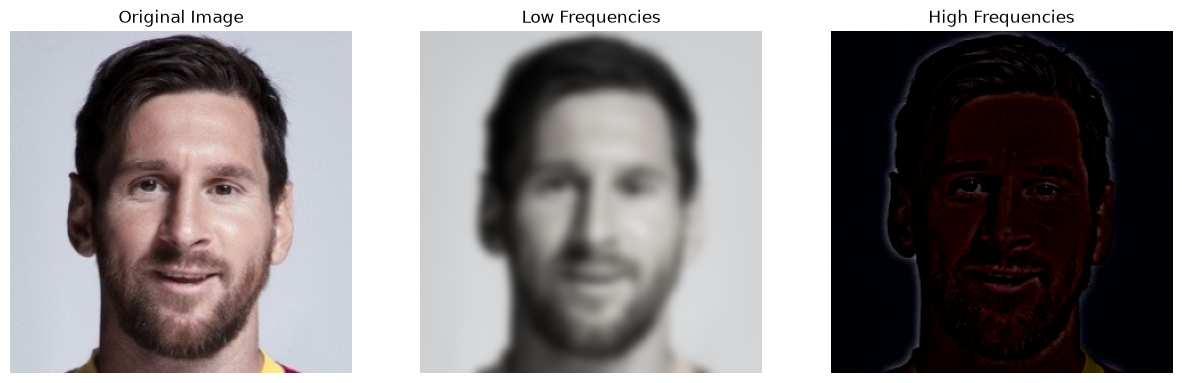

In [16]:
# Import the necessary libraries
from skimage import io
from skimage.color import rgb2gray
from skimage.filters import gaussian
from skimage.transform import resize

# Load the original Messi image
messi = io.imread("images_notebook/messi.jpg")

# Resize the image to a common size of 300x300 pixels
# This makes the image easier to process and compare
messi = resize(messi, (300, 300))

# Apply a Gaussian filter to remove high-frequency information
# The result contains mainly the low-frequency components:
# smooth regions, gradual intensity changes, and large structures.
# A larger sigma produces stronger blurring.
messi_low = gaussian(messi, sigma=4)

# Obtain the high-frequency components by subtracting
# the low-frequency image from the original image.
#
# Original image = Low frequencies + High frequencies
# Therefore:
# High frequencies = Original image - Low frequencies
messi_high = messi - messi_low

# Create a figure containing 3 images arranged in a 1x3 grid
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Display the original image
ax[0].imshow(messi)

# Remove the x and y axis ticks
ax[0].axis("off")

# Add a title
ax[0].set_title("Original Image")

# Display the low-frequency component
# This image is blurred because high-frequency details
# such as edges and fine textures have been removed.
ax[1].imshow(messi_low)

# Remove the x and y axis ticks
ax[1].axis("off")

# Add a title
ax[1].set_title("Low Frequencies")

# Display the high-frequency component
# This contains mainly edges, fine details, textures,
# and potentially some noise.
ax[2].imshow(messi_high)

# Remove the x and y axis ticks
ax[2].axis("off")

# Add a title
ax[2].set_title("High Frequencies")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5511435250926116..0.501787444257863].


Text(0.5, 1.0, 'High Frequencies')

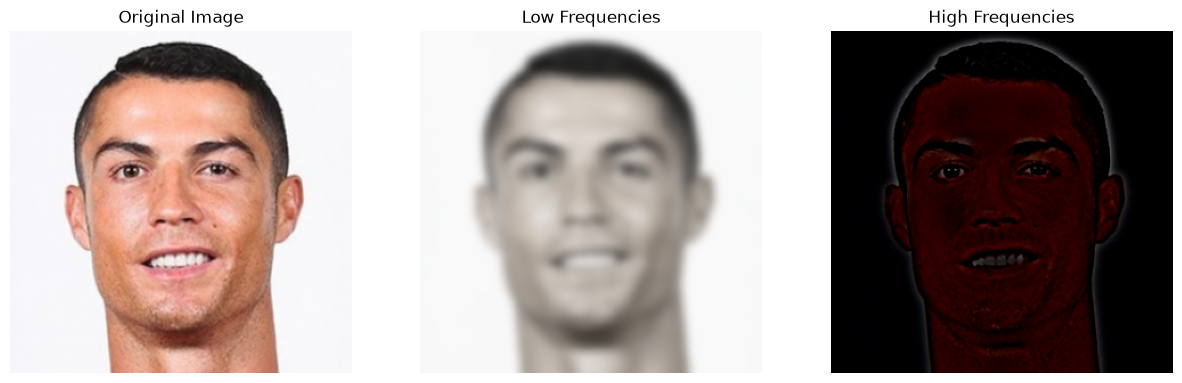

In [17]:
# Load the CR7 image
cr = io.imread("images_notebook/cr.jpg")

# Resize the image to a common size of 300x300 pixels
# This ensures that the image has a consistent size for processing
cr = resize(cr, (300, 300))

# Apply a Gaussian filter to blur the image
# This removes high-frequency information such as edges and fine details
# The remaining image mainly contains low-frequency information
cr_low = gaussian(cr, sigma=4)

# Obtain the high-frequency components of the image
# High frequencies = Original image - Low frequencies
# These components mainly contain edges, textures, and fine details
cr_high = cr - cr_low

# Create a figure with 3 images arranged in a 1x3 grid
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Display the original image
ax[0].imshow(cr)

# Remove the x and y axes and their ticks
ax[0].axis("off")

# Set the title of the first image
ax[0].set_title("Original Image")


# Display the low-frequency component
# This image is smoother because the Gaussian filter
# has removed most of the high-frequency details
ax[1].imshow(cr_low)

# Remove the x and y axes and their ticks
ax[1].axis("off")

# Set the title of the second image
ax[1].set_title("Low Frequencies")


# Display the high-frequency component
# This image contains mainly edges, fine details, and textures
# obtained by subtracting the low-frequency image from the original
ax[2].imshow(cr_high)

# Remove the x and y axes and their ticks
ax[2].axis("off")

# Set the title of the third image
ax[2].set_title("High Frequencies")

**b)** Create hybrid images and visualize them. A hybrid image is obtained by combining the low and high frequencies of the image, i.e. combining the results obtained by the `low-pass` and `high-pass` filters.

<img src="images_notebook/Fusion.gif" width="400" height="400">

***Hybrid (I1, I2) = L(I1) + H(I2)***



### Exercise: Create Hybrid Images

Using the low- and high-frequency components obtained from the `messi` and `cr` images, create two hybrid images.

1. Create **Hybrid Image 1** by combining the low-frequency component of `cr` with the high-frequency component of `messi`, giving both components equal weight (`0.5`).
2. Create **Hybrid Image 2** by combining the low-frequency component of `messi` with the high-frequency component of `cr`, also giving both components equal weight (`0.5`).
3. Multiply each result by `2` to compensate for the averaging.
4. Display both hybrid images side by side in a `1 × 2` grid, without axes, and with appropriate titles.

> Expected result is shown below:

<img src="images_notebook/Hybrid.png" height="200">


> Hybrid images can be used in **visual illusions, art and design, advertising, visual perception research, and computer vision applications**, where different details are perceived at different viewing distances.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.003735119528399458..1.2806954618366069].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.3441909329515266..1.149651065013968].


Text(0.5, 1.0, 'Hybrid Image 2')

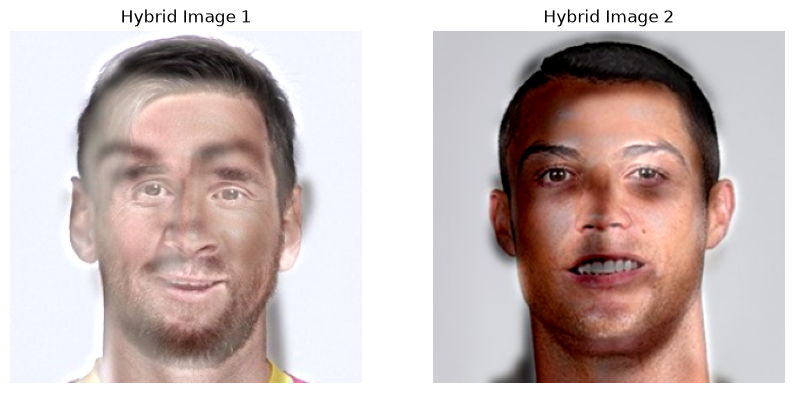

In [18]:
# Create the first hybrid image by combining:
# - The low-frequency information from the CR7 image
# - The high-frequency information from the Messi image
#
# 0.5 gives equal weight to both components.
# Multiplying by 2 compensates for the averaging and increases
# the overall intensity of the resulting image.
hybrid_1 = 2 * (0.5 * cr_low + 0.5 * messi_high)


# Create the second hybrid image by combining:
# - The low-frequency information from the Messi image
# - The high-frequency information from the CR7 image
#
# Again, both components have equal weight (0.5).
# The factor 2 increases the intensity of the result.
hybrid_2 = 2 * (0.5 * messi_low + 0.5 * cr_high)


# Create a figure containing the two hybrid images
# arranged side by side in a 1x2 grid.
fig, ax = plt.subplots(1, 2, figsize=(10, 5))


# Display the first hybrid image
ax[0].imshow(hybrid_1)

# Remove the x and y axes and their ticks
ax[0].axis("off")

# Add a title to the first hybrid image
ax[0].set_title("Hybrid Image 1")

# Display the second hybrid image
ax[1].imshow(hybrid_2)

# Remove the x and y axes and their ticks
ax[1].axis("off")

# Add a title to the second hybrid image
ax[1].set_title("Hybrid Image 2")

## **2.7 Anonimization of sensitive information**

One of the important problems in Computer Vision as a science that manages data (images and videos) is the anonimization of sensitive information appearing in the images.
For example, it is common in applications like Google Street View, where the faces and license plates are anonymized.
The file `./images_notebook/car.png` contains two cars. Anonimize the license plates of the cars using the techniques learned in this practicum.

Modify only the license plates of the cars, keeping the rest of the image unchanged.

Expected result is illustrated below:

<img src="images_notebook/anonimyzed.jpg" height="350">

(473, 806, 3)


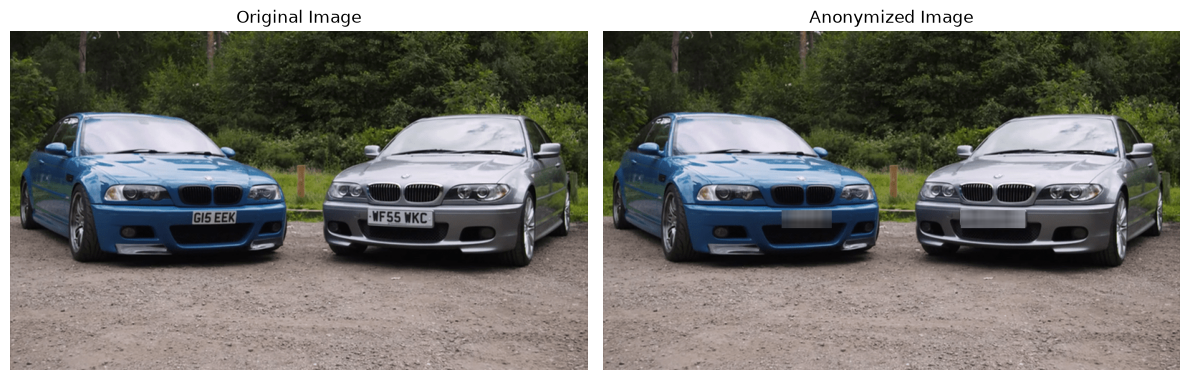

In [19]:
# Load the image from the specified file path
image = io.imread("images_notebook/car.png")

# Print the dimensions of the image
# For a color image, this is usually: (height, width, channels)
print(image.shape)


# Convert the image to floating-point values
# This makes the image easier and safer to manipulate during filtering.
# Pixel values are typically converted to the range [0, 1].
image_float = img_as_float(image)


# Define the coordinates of the license plates manually.
# Each region is defined by:
# ((start_row, start_col), (end_row, end_col))
#
# The first region corresponds to the first car's license plate.
license_plate_1 = ((250, 250), (275, 320))

# Coordinates of the second car's license plate.
license_plate_2 = ((250, 500), (275, 590))


# Define a function to anonymize a rectangular region of an image.
def anonymize_region(image, top_left, bottom_right):
    """
    Blur a selected region of the image to anonymize it.
    
    top_left: coordinates of the top-left corner (row, column)
    bottom_right: coordinates of the bottom-right corner (row, column)
    """

    # Extract only the selected license-plate region
    region = image[
        top_left[0]:bottom_right[0],
        top_left[1]:bottom_right[1]
    ]

    # Create a 25 × 25 averaging mask.
    # A larger mask produces stronger smoothing/blur.
    mask_3d = np.ones((25, 25))

    # Apply convolution to the selected region.
    # This smooths the pixels and makes the license plate unreadable.
    blurred_region = conv_coor(region, mask_3d)

    # Replace the original license-plate region
    # with the blurred version.
    image[
        top_left[0]:bottom_right[0],
        top_left[1]:bottom_right[1]
    ] = blurred_region


# Blur the first license plate
anonymize_region(
    image_float,
    license_plate_1[0],
    license_plate_1[1]
)

# Blur the second license plate
anonymize_region(
    image_float,
    license_plate_2[0],
    license_plate_2[1]
)


# Create a figure with two images side by side.
fig, ax = plt.subplots(1, 2, figsize=(12, 6))


# Display the original image on the left.
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")  # Hide x and y axes


# Display the anonymized image on the right.
# The license plates should now appear blurred.
ax[1].imshow(image_float)
ax[1].set_title("Anonymized Image")
ax[1].axis("off")


# Adjust the spacing between the two images
# and display the final figure.
plt.tight_layout()
plt.show()